In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [85]:
df=pd.read_csv("insurance.csv")


In [86]:
df.head()


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [87]:
df.shape

(1338, 7)

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [88]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [89]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


<Axes: ylabel='bmi'>

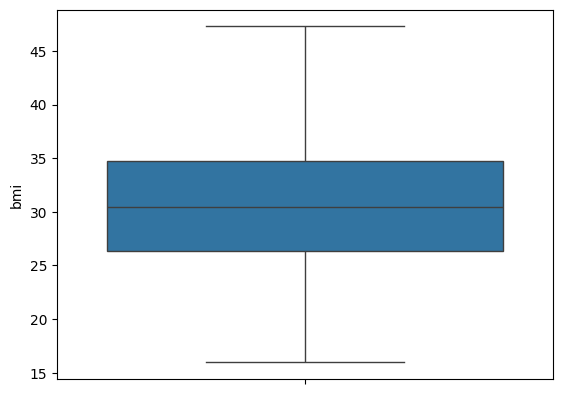

In [97]:
sns.boxplot(df['bmi'])

In [91]:
Q3=df['bmi'].quantile(0.75)
Q1=df['bmi'].quantile(0.25)
IQR=Q3-Q1
UL=Q3+1.5*IQR
LL=Q1-1.5*IQR


In [92]:
df['bmi']=df['bmi'].clip(LL,UL)

<Axes: ylabel='charges'>

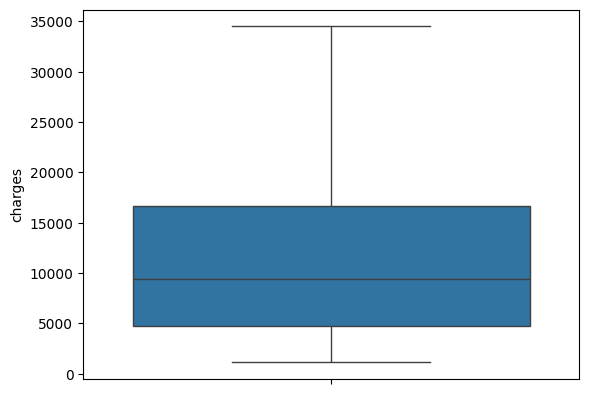

In [96]:
sns.boxplot(df['charges'])

In [94]:
Q3=df['charges'].quantile(0.75)
Q1=df['charges'].quantile(0.25)
IQR=Q3-Q1
UL=Q3+1.5*IQR
LL=Q1-1.5*IQR

In [99]:
df['charges']=df['charges'].clip(LL,UL)

In [100]:
df.duplicated().sum()

np.int64(1)

In [101]:
df=df.drop_duplicates()

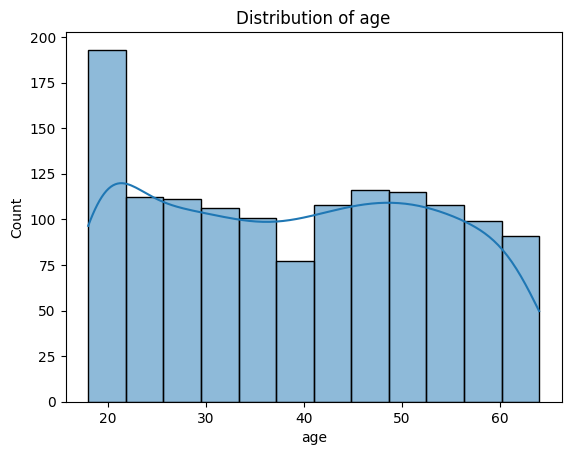

In [102]:
sns.histplot(df['age'],kde=True)
plt.title('Distribution of age')
plt.show()



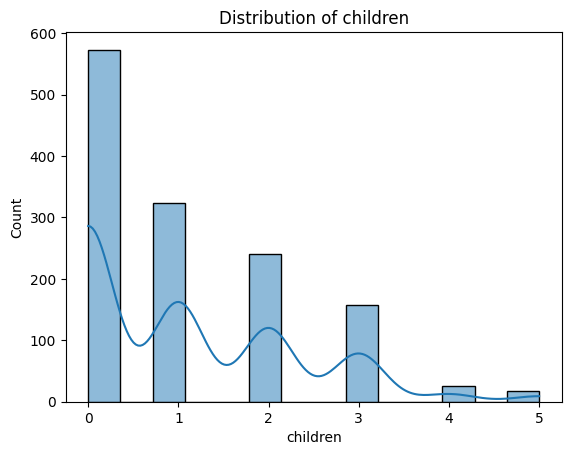

In [103]:
sns.histplot(df['children'], kde=True)
plt.title('Distribution of children')
plt.show()


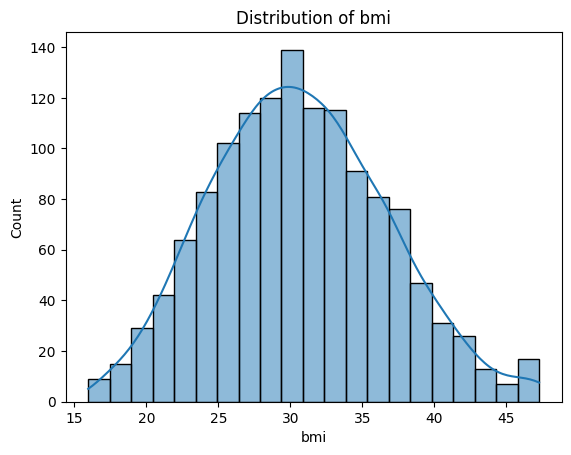

In [104]:
sns.histplot(df['bmi'], kde=True)
plt.title('Distribution of bmi')
plt.show()


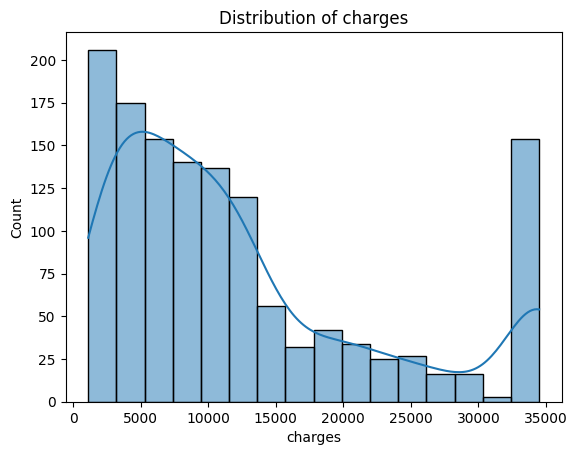

In [105]:
sns.histplot(df['charges'], kde=True)
plt.title('Distribution of charges')
plt.show()

<Axes: xlabel='smoker', ylabel='count'>

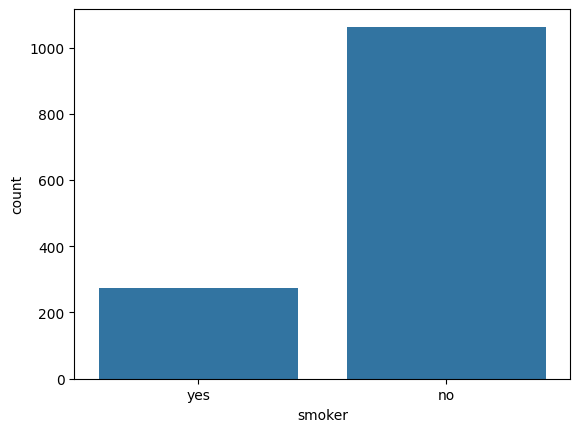

In [57]:
sns.countplot(x = df['smoker'])

<Axes: xlabel='sex', ylabel='count'>

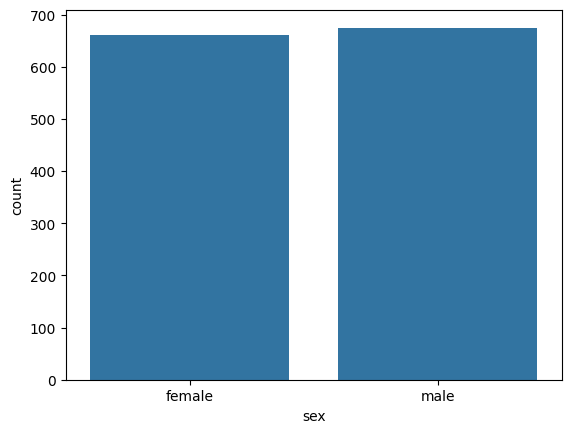

In [58]:
sns.countplot(x = df['sex'])

<Axes: ylabel='age'>

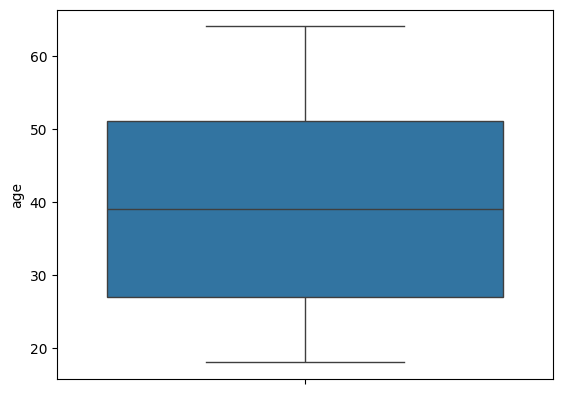

In [60]:
sns.boxplot(df['age'])

<Axes: ylabel='bmi'>

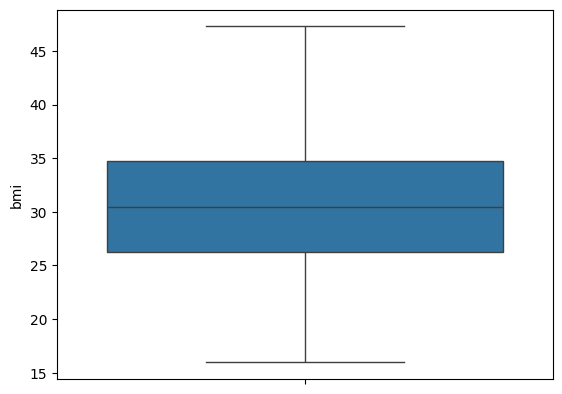

In [61]:
sns.boxplot(df['bmi'])

<Axes: ylabel='children'>

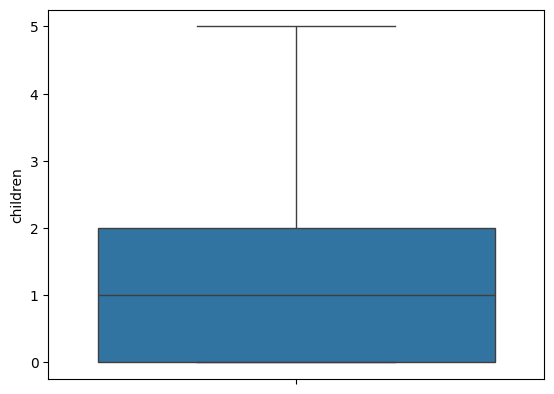

In [62]:
sns.boxplot(df['children'])

<Axes: ylabel='charges'>

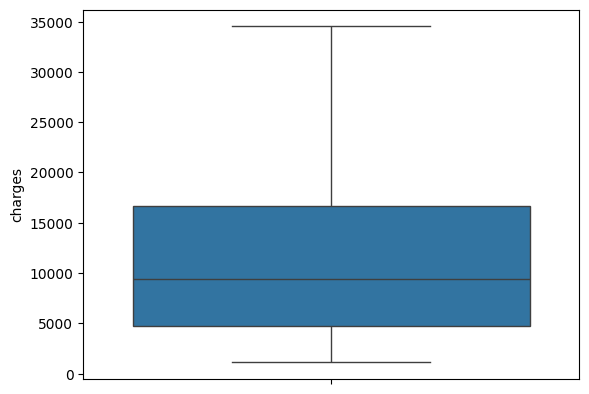

In [63]:
sns.boxplot(df['charges'])

<Axes: >

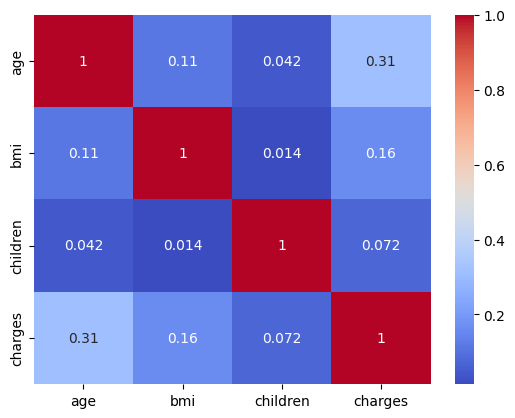

In [64]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')

In [79]:
def age_group(age):
  if age <   30:
    return 'Young'
  elif age < 50:
    return 'Middle age'
  else:
   return 'senior'

df['age_group']=df['age'].apply(age_group)



In [82]:
def bmi_category(bmi):
    if bmi < 18.5:
        return 'Underweight'
    elif bmi < 25:
        return 'Normal'
    elif bmi < 30:
        return 'Overweight'
    else:
        return 'Obese'

df['bmi_category'] = df['bmi'].apply(bmi_category)

In [83]:
df

,age,sex,bmi,children,smoker,region,charges,age_group,bmi_category
0,19,female,27.900,0,yes,southwest,16884.92400,Young,Overweight
1,18,male,33.770,1,no,southeast,1725.55230,Young,Obese
2,28,male,33.000,3,no,southeast,4449.46200,Young,Obese
3,33,male,22.705,0,no,northwest,21984.47061,Middle age,Normal
4,32,male,28.880,0,no,northwest,3866.85520,Middle age,Overweight
...,...,...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830,senior,Obese
1334,18,female,31.920,0,no,northeast,2205.98080,Young,Obese
1335,18,female,36.850,0,no,southeast,1629.83350,Young,Obese
1336,21,female,25.800,0,no,southwest,2007.94500,Young,Overweight


### Key Insights

1. **Age Distribution:** Most individuals in the dataset fall within the adult and middle-age groups, with fewer observations at the higher age range.

2. **BMI Distribution:** BMI is approximately normally distributed, with most individuals having BMI values around 25–35.

3. **Medical Charges:** Insurance charges are right-skewed, meaning most individuals have relatively lower charges while a smaller group has very high medical expenses.

4. **Smoking and Charges:** Smoking status appears to have a strong relationship with insurance charges, with smokers generally having substantially higher charges than non-smokers.

5. **Feature Engineering:** New features such as `age_group` and `bmi_category` help group continuous variables into meaningful categories, making it easier to analyze patterns in insurance charges.